# Week 3 — Multi-mode noise injection pipeline
    **Donovan Marshall · DEV.BAFAD290.01**

    Source: [Week 3 exercise](https://uncfsu.instructure.com/courses/53036/files/10618842?wrap=1).
    Synthetic binary labels drive both injection modes. This exercise simulates
    Gaussian noise and missing sensor readings; no trained detector is used.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
print(f'NumPy version: {np.__version__}')
print('Imports successful.')


NumPy version: 1.26.4
Imports successful.


## Baseline stream


In [2]:
def generate_sensor_stream(samples=1000, features=3, seed=42):
    """Generate the course baseline: (time steps, sensor channels)."""
    np.random.seed(seed)
    t = np.linspace(0, 50, samples)
    stream = np.zeros((samples, features))
    for f in range(features):
        stream[:, f] = np.sin(t * (f + 1)) + np.random.normal(0, 0.05, samples)
    return stream

clean_stream = generate_sensor_stream(samples=1000, features=3)
print(f'Clean stream shape: {clean_stream.shape}')
print(f'Value range: [{clean_stream.min():.3f}, {clean_stream.max():.3f}]')
assert clean_stream.shape == (1000, 3)
print('Shape assertion passed.')


Clean stream shape: (1000, 3)
Value range: [-1.126, 1.157]
Shape assertion passed.


## Binary anomaly labels


In [3]:
labels = np.zeros(1000, dtype=int)
labels[200:280] = 1
labels[600:750] = 1
print(f'Total anomaly rows: {labels.sum()}')
print(f'Anomaly fraction: {labels.mean():.3f}')
assert labels.sum() == 230
print('Label assertion passed.')


Total anomaly rows: 230
Anomaly fraction: 0.230
Label assertion passed.


## Convert contiguous positive labels into half-open intervals


In [4]:
def extract_anomaly_windows(anomaly_labels):
    """Return one (start, exclusive_end) pair for every contiguous run of 1s."""
    windows = []
    in_window = False
    start = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows

windows = extract_anomaly_windows(labels)
print(f'Extracted windows: {windows}')
assert len(windows) == 2
assert windows[0] == (200, 280)
assert windows[1] == (600, 750)
assert extract_anomaly_windows([]) == []
assert extract_anomaly_windows([0, 0, 0]) == []
assert extract_anomaly_windows([1, 1, 1]) == [(0, 3)]
assert extract_anomaly_windows([0, 1, 1]) == [(1, 3)]
assert extract_anomaly_windows([1, 0, 1]) == [(0, 1), (2, 3)]
print('Required window assertions and boundary-case checks passed.')


Extracted windows: [(200, 280), (600, 750)]
Required window assertions and boundary-case checks passed.


## Apply noise or blackout without changing the input


In [5]:
def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Copy a sensor stream and alter only [start_idx, end_idx).

    For noise, variance retains the course API's standard-deviation meaning.
    Blackout fills the requested window with exact zeros.
    """
    poisoned_data = raw_data.copy()
    window_rows = end_idx - start_idx
    n_features = poisoned_data.shape[1]
    if mode == 'noise':
        noise = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += noise
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'. Choose 'noise' or 'blackout'.")
    return poisoned_data

original = clean_stream.copy()
np.random.seed(42)
noisy_stream = clean_stream.copy()
blackout_stream = clean_stream.copy()
for start, end in windows:
    noisy_stream = inject_noise_profile(noisy_stream, start, end,
                                        variance=2.5, mode='noise')
    blackout_stream = inject_noise_profile(blackout_stream, start, end,
                                           mode='blackout')
assert noisy_stream.shape == clean_stream.shape
assert blackout_stream.shape == clean_stream.shape
for left, right in [(0, 200), (280, 600), (750, 1000)]:
    assert np.array_equal(noisy_stream[left:right], clean_stream[left:right])
    assert np.array_equal(blackout_stream[left:right], clean_stream[left:right])
for start, end in windows:
    assert np.all(blackout_stream[start:end, :] == 0.0)
    clean_mag = np.abs(clean_stream[start:end]).mean()
    noisy_mag = np.abs(noisy_stream[start:end]).mean()
    assert noisy_mag > clean_mag
    print(f'Window [{start}, {end}): clean={clean_mag:.4f}, noisy={noisy_mag:.4f}')
assert np.array_equal(clean_stream, original)
try:
    inject_noise_profile(clean_stream, 0, 1, mode='unknown')
except ValueError:
    print('Invalid mode correctly raises ValueError.')
else:
    raise AssertionError('An unsupported mode must raise ValueError')
print('All required assertions passed for both modes; input is unchanged.')


Window [200, 280): clean=0.6539, noisy=2.0498
Window [600, 750): clean=0.6436, noisy=2.0865
Invalid mode correctly raises ValueError.
All required assertions passed for both modes; input is unchanged.


## Three-panel comparison
Both label-derived windows are shaded in every panel.


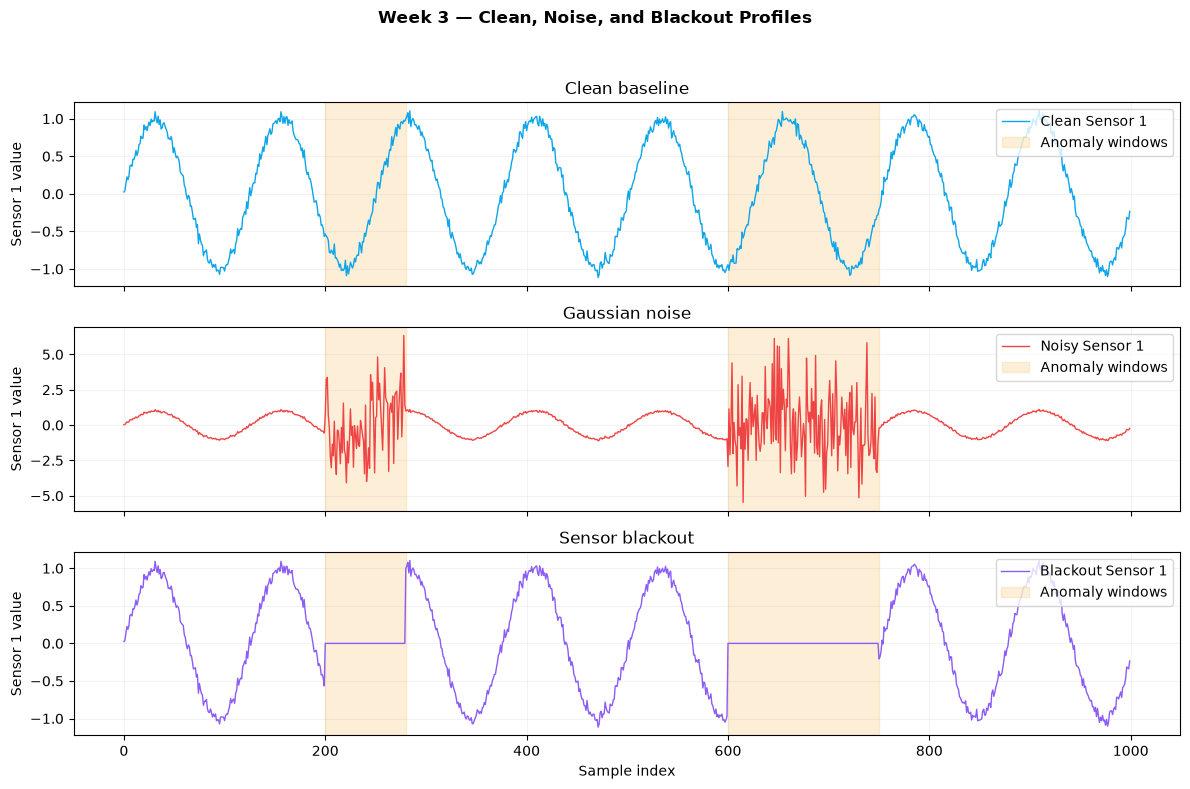

Plot saved: week03_exercise1_plot.png


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
t = np.arange(clean_stream.shape[0])
panels = [
    (clean_stream, '#0EA5E9', 'Clean Sensor 1', 'Clean baseline'),
    (noisy_stream, '#EF4444', 'Noisy Sensor 1', 'Gaussian noise'),
    (blackout_stream, '#8B5CF6', 'Blackout Sensor 1', 'Sensor blackout')
]
for ax, (values, color, label, title) in zip(axes, panels):
    ax.plot(t, values[:, 0], color=color, linewidth=1.0, label=label)
    for i, (start, end) in enumerate(windows):
        ax.axvspan(start, end, color='#F59E0B', alpha=0.16,
                   label='Anomaly windows' if i == 0 else None)
    ax.set_ylabel('Sensor 1 value')
    ax.set_title(title)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.15)
axes[-1].set_xlabel('Sample index')
fig.suptitle('Week 3 — Clean, Noise, and Blackout Profiles', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig('week03_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved: week03_exercise1_plot.png')


## Interpretation
    ### Q1 — Comparing the modes
    Noise produces irregular spikes around the original waveform; blackout makes
    each anomaly window a flat zero line. A model trained on clean patterns would
    generally have large reconstruction errors for strong noise, while blackout
    errors depend on the signal that should have been present. A blackout near a
    natural zero crossing can be harder to detect, so lower observed magnitude
    does not establish that a missing-sensor event is harmless.

    ### Q2 — Different window lengths
    No function changes are needed for the 80- and 150-sample windows. The noise
    array is sized from `end_idx - start_idx` and the input feature count, while
    blackout fills the same parameterized slice. The exclusive end index gives
    the correct number of rows for either window length.

    ### Q3 — No anomaly labels
    An all-zero label array produces an empty list of windows. Iterating over that
    list runs the injection loop zero times, so both stream copies remain equal
    to the clean input. The original array also remains unchanged.
